# 05. Pairwise Entity-Resolution Model — Hybrid Self-Supervised Classifier

**Course:** CSE 276 – CA-1 Academic Project
**Project:** Material Code Harmonisation Across Public Enterprises (IOCL, OIL, NTPC)
**Status:** ✅ Model trained, evaluated and serialised (`models/hybrid_er_model.joblib`)

---

### The problem this notebook solves
Earlier versions of this notebook kept supervised training *locked*: only **20 human-confirmed binary labels** exist (2 positives, 18 negatives) — far too few to fit, let alone evaluate, a classifier. Training on the AI-suggested hypotheses would violate the project's integrity policy.

### The solution: self-supervised labels *by construction*
Following self-supervised entity-matching practice (data augmentation in *Ditto*, Li et al. 2020; contrastive pre-training in *Sudowoodo*, Wang et al. 2023), we generate training pairs **from the real 6,634-record candidate pool** whose labels are known with certainty because of *how they were made* — not because a human or an AI judged them:

| Pair type | How it is built | Label | Why the label is certain |
|---|---|---|---|
| **Positive** | real record vs. a *format-only rewrite* of itself (boilerplate, quantity suffix, SAP noun-first order, abbreviations, unit spacing, typo, plural) | 1 | the physical item is unchanged |
| **Hard negative** | real record vs. a rewrite with **exactly one specification changed** (250MM→300MM, SS304→SS316, CLASS 150→300, BALL→GATE valve, API 6D→6A …) | 0 | different specification ⇒ not functionally equivalent (project definition) |
| **Real spec-conflict negative** | real candidate pair whose canonical number+unit specs are disjoint (e.g. 1400MM vs 1800MM belts) | 0 | explicit, parsed specification conflict |
| **Random cross-commodity negative** | two real records from different commodity classes (pump vs cable) | 0 | different commodity |

**Integrity guarantees:** (1) no human or AI label is used for fitting; (2) all 173 records of the human review set — and any record sharing their description text — are excluded from training, so the review-set evaluation is untouched; (3) train/val/test are split by *near-duplicate group* (union-find over TF-IDF ≥ 0.8), so no record or near-copy appears on both sides.


In [1]:

import sys, json, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Colab environment setup
if "google.colab" in sys.modules:
    colab_repo = Path("/content/CSE-276-PROJECT")
    if not colab_repo.is_dir():
        subprocess.run(["git", "clone", "https://github.com/SHIVA07605/CSE-276-PROJECT.git", str(colab_repo)], check=True)
    os.chdir(str(colab_repo))
    req_file = colab_repo / "requirements.txt"
    if req_file.exists():
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(req_file)], check=True)
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz", "sentence-transformers"], check=True)

# Locate project root whether the kernel starts in notebooks/ or in the repository root
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)


Project root: C:\project ai


---
## Section A — Run the end-to-end training pipeline
`src/er_pipeline.run_training()` executes every stage (data → pairs → MiniLM embeddings → 38 hybrid features → 3 classifiers → threshold selection → evaluation → scoring of all 22,464 real candidate pairs → conflict-aware clustering) and saves every artefact. The same function is used by `python train_er_model.py`, so the numbers in this notebook and on disk are identical.

In [2]:
from src.er_pipeline import run_training
R = run_training(verbose=True, save=True)

[1/7] Loading project data ...


      candidate pool=6,634  candidate pairs=22,464  review pairs=150  excluded review IDs=173


[2/7] Building self-supervised training pairs (labels by construction) ...


      pairs=10,562  by source={'synthetic_positive': 6599, 'synthetic_hard_negative': 1812, 'random_cross_commodity_negative': 1344, 'real_spec_conflict_negative': 807}


      by split={'train': 7546, 'test': 1508, 'val': 1508}  positives=6,599


[3/7] Embedding texts (MiniLM) and computing hybrid features ...


... (13 outputs left out)

[7/7] Scoring all real candidate pairs and building harmonised master ...


      decisions={'NOT_EQUIVALENT': 16911, 'NEEDS_REVIEW': 4640, 'EQUIVALENT': 913}  multi-record clusters=374


[OK] Saved model -> C:\project ai\models\hybrid_er_model.joblib


[DONE] Pipeline finished in 137.0s


---
## Section B — The self-supervised training corpus

In [3]:
pairs = R["pairs"]
summary = (pairs.groupby(["source", "label"]).size().unstack(fill_value=0)
           .rename(columns={0: "negatives (0)", 1: "positives (1)"}))
display(summary)
display(pairs.groupby("split")["label"].agg(pairs="size", positives="sum").assign(negatives=lambda d: d.pairs - d.positives))
print("Group leakage between train and val/test:", R["metrics"]["training_data"]["group_leakage"], "groups")
print("Excluded human-review record IDs       :", R["metrics"]["training_data"]["excluded_review_ids"])

label,negatives (0),positives (1)
source,,
random_cross_commodity_negative,1344,0
real_spec_conflict_negative,807,0
synthetic_hard_negative,1812,0
synthetic_positive,0,6599


,pairs,positives,negatives
split,,,
test,1508,1015,493
train,7546,4627,2919
val,1508,957,551


Group leakage between train and val/test: 0 groups
Excluded human-review record IDs       : 173


In [4]:
# Concrete examples of each pair type (raw strings as generated, before normalisation)
cols = ["source", "label", "raw_a", "raw_b", "aug_ops_b", "mutation_group", "mutation_old", "mutation_new"]
for src in ["synthetic_positive", "synthetic_hard_negative", "real_spec_conflict_negative", "random_cross_commodity_negative"]:
    print(f"\n### {src}")
    display(pairs.loc[pairs.source == src, cols].sample(4, random_state=7))


### synthetic_positive


,source,label,raw_a,raw_b,aug_ops_b,mutation_group,mutation_old,mutation_new
7933,synthetic_positive,1,COILED TUBING UNIT SPARES (NOS.),"PROCUREMENT OF SPARES, COILED TUBNG UNIT",noun_first_reorder|typo|boilerplate_prefix,,,
4546,synthetic_positive,1,BIDS FOR THE SUPPLY OF 9.5 8 244.475MM API 5CT N-80 TYPE-I TYPE-Q ...,PURCHASE OF BIDS FOR THE SUPPLY OF 9.5 8 244.475 mm API 5CT N-80 T...,boilerplate_prefix|unit_format|typo,,,
2891,synthetic_positive,1,SERVICES FOR ROAD TRANSPORTATION OF GOODS & EQUPIMENT CHEMICALS CE...,SERVICES ROAD TRANSPORTATINO OF GOODS & EQUIPMENT CHEMICALS CEMENT...,typo|filler_drop,,,
2567,synthetic_positive,1,ELECTRICAL MOTOR DRIVEN SCREW AIR COMPRESSOR,Electrical Motor Driven Screw Air Compressor,casing,,,



### synthetic_hard_negative


,source,label,raw_a,raw_b,aug_ops_b,mutation_group,mutation_old,mutation_new
7084,synthetic_hard_negative,0,VALVE PLUG 2INCH X 150 CLASS (Q3) PLUG VALVE 2INCH X 300 CLASS (Q3...,PLUG VALVE 2INCH X 150 CLASS (Q3) PLUG VALVE 2INCH X 300 CLASS (Q3...,,INCH,4,8
4840,synthetic_hard_negative,0,CONSTRUCTION OF 1000 KL CAPACITY RCC OVERHEAD WATER TANK INSIDE OI...,CONSTRUCTION OF 2500 KL CAPACITY RCC OVERHEAD WATER TANK INSIDE OI...,,FACTOR,1000,2500
524,synthetic_hard_negative,0,"'CONVEYOR BELT (NN/ EP) UPTO 1400MM WIDTH"" WITH AVERAGE ANNUAL TUR...","'CONVEYOR BELT (NN/ EP) UPTO 1000MM WIDTH"" WITH AVERAGE ANNUAL TUR...",,MM,1400,1000
3451,synthetic_hard_negative,0,380 HP ELECTRIICAL MOTOR,190 HP ELECTRICAL MOTOR,,FACTOR,380,190



### real_spec_conflict_negative


,source,label,raw_a,raw_b,aug_ops_b,mutation_group,mutation_old,mutation_new
8519,real_spec_conflict_negative,0,CABLE 4C X 16 SQMM 1100V PVCA ALU,CABLE 4C X 10 SQMM 1100V PVCA ALU,,real_conflict,,
8553,real_spec_conflict_negative,0,RAVASCO TRANSMISSION LTD. VAPI A FABRIC BELT UPTO 2200MM WIDTH,SEMPELTRAN NIRLON MUMBAI A FABRIC BELT UPTO 1600MM WIDTH,,real_conflict,,
8579,real_spec_conflict_negative,0,10_ HAMMER LUG UNION 2INCH X FIG 1502M 20_ HCR VALVE ASSY 2.1/16IN...,BLIND FLANGE ASSY 3.1/16INCH X 10M,,real_conflict,,
8766,real_spec_conflict_negative,0,LINE PIPE - 3/4INCH ERW GALVANISED,LINE PIPE 2INCH ERW GALVANISED SCREWED (Q3),,real_conflict,,



### random_cross_commodity_negative


,source,label,raw_a,raw_b,aug_ops_b,mutation_group,mutation_old,mutation_new
9786,random_cross_commodity_negative,0,SAE 40 LUBE OIL FOR HEAVY FUEL OIL ENGINES,VALVE FOR DRILLING AND PRODUCTION SERVICE THROUGH CONDUIT - ROUND ...,,random,,
9782,random_cross_commodity_negative,0,BIDS FOR SUPPLY AND INSTALLATION AND COMMISSIONING OF AIR COMPRESS...,COVER & BASE OF CONCRETE SAFETY ENCLOSURE FOR X-MASS TREE,,random,,
9531,random_cross_commodity_negative,0,CAMERA FOR CCTV SYSTEM (Q2) VIDEO RECORDER FOR CCTV SYSTEM-IS 9000...,ERW LINE PIPE OF NOM. SIZES 6INCH API-5L FOR TOTAL QUANTITY OF 3 400M,,random,,
9766,random_cross_commodity_negative,0,SPARES FOR BHEL SUPPLIED 10M & 5M CHOKE & KILL MANIFOLD CONFORMING...,6INCH ERW GALVANISED LINE PIPE - 8 500M,,random,,


---
## Section C — Hybrid feature vector (38 features)

| Family | Features | Purpose |
|---|---|---|
| Semantic | `sem_cosine`, `sem_minus_lex` | MiniLM meaning; synonym / phrasing-inversion gap |
| Lexical | word & char TF-IDF cosine, Jaccard, containment, 4 fuzzy ratios, lengths, exact match | surface overlap, robust to typos & reordering |
| Token differences | `alpha_symdiff`, `alpha_unmatched_fuzzy`, bare-number Jaccard / symdiff | detects a changed descriptor or number |
| Canonical specifications | unit-spec matches / **conflicts** / partial / one-side; descriptor-group matches / **conflicts** / one-side; standards, grades, bearing series; identity-spec counts | unit-aware: `10 MM`=`10MM`, `1.1 KV`=`1100V`, `CLASS 150`=`150#` |
| Project rule signals | `PrecisionMatchingEngine` decision & conflict counts; legacy regex attribute matches / conflicts | reuses Notebook 04–06 domain rules |

**The classifier is trained on 34 of the 38 features.** Four are computed but used *only* by the decision-policy safety gates:
* `identity_spec_min/max` — only specification-rich records can be mutated into hard negatives, so raw spec counts would let the classifier learn a *construction shortcut* ("many specs ⇒ non-match"). Spec-rich seeds also receive a second positive for the same reason.
* `legacy_attr_matches/conflicts` — the original string-equality extractor reports false conflicts on equivalent formats (`150#` vs `CLASS 150`, `101.60MM` vs `101.6MM`); the canonical unit-aware features supersede it.

No IDs, enterprise names, tender numbers or labels are used (leakage guard).

In [5]:
X_all, y_all = R["X_all"], R["y_all"]
key = ["sem_cosine", "tfidf_word_cosine", "fuzz_token_set", "alpha_unmatched_fuzzy", "unit_spec_conflicts",
       "group_conflicts", "standard_conflicts", "identity_spec_max", "engine_not_equivalent"]
display(X_all[key].groupby(y_all).mean().rename(index={0: "mean | label 0", 1: "mean | label 1"}).T.round(3))
print("Feature matrix:", X_all.shape, "| all finite:", bool(np.isfinite(X_all.values).all()))

,mean | label 0,mean | label 1
sem_cosine,0.648,0.935
tfidf_word_cosine,0.468,0.884
fuzz_token_set,0.708,0.963
alpha_unmatched_fuzzy,7.366,0.067
unit_spec_conflicts,0.446,0.000
group_conflicts,0.088,0.000
standard_conflicts,0.014,0.000
identity_spec_max,1.003,0.567
engine_not_equivalent,0.326,0.000


Feature matrix: (10562, 38) | all finite: True


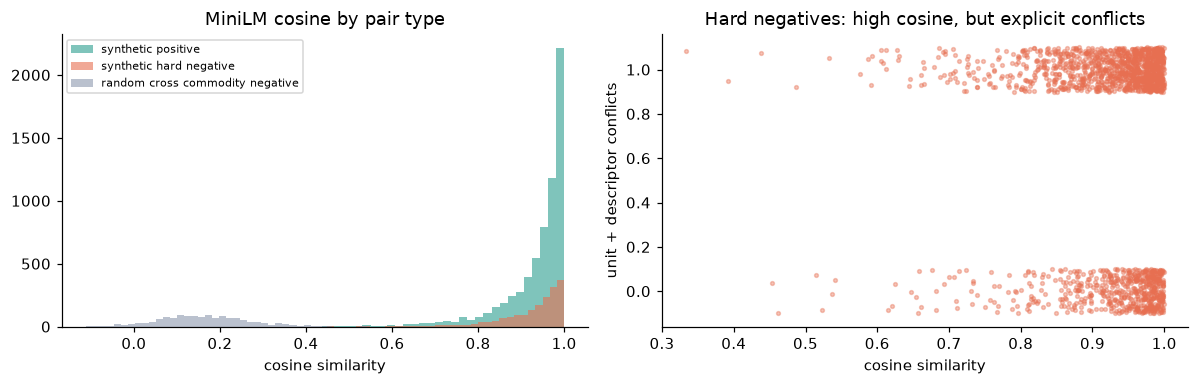

In [6]:
# The semantic-masking problem from Notebook 04, visible in the training data:
# hard negatives are almost as similar as positives in MiniLM space -> embeddings alone cannot decide.
src = R["pairs"]["source"].values
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s, c in [("synthetic_positive", "#2a9d8f"), ("synthetic_hard_negative", "#e76f51"), ("random_cross_commodity_negative", "#8d99ae")]:
    ax[0].hist(X_all.loc[src == s, "sem_cosine"], bins=40, alpha=0.6, label=s.replace("_", " "), color=c)
ax[0].set_title("MiniLM cosine by pair type"); ax[0].set_xlabel("cosine similarity"); ax[0].legend(fontsize=7)
hn = src == "synthetic_hard_negative"
ax[1].scatter(X_all.loc[hn, "sem_cosine"], X_all.loc[hn, "unit_spec_conflicts"] + X_all.loc[hn, "group_conflicts"] + np.random.RandomState(0).uniform(-.1, .1, hn.sum()), s=6, alpha=.4, color="#e76f51")
ax[1].set_title("Hard negatives: high cosine, but explicit conflicts"); ax[1].set_xlabel("cosine similarity"); ax[1].set_ylabel("unit + descriptor conflicts")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_semantic_masking_training_pairs.png", bbox_inches="tight"); plt.show()

---
## Section D — Model training & selection (validation split)
Three classifiers are trained on the **train** split with balanced class weights and compared on the **validation** split; the model with the highest validation PR-AUC is selected. The test split is not touched here.

In [7]:
display(R["val_table"][["precision", "recall", "f1", "roc_auc", "pr_auc", "threshold", "train_seconds"]].round(4))
print("Selected model:", R["best_name"])
print("Decision thresholds (chosen on validation only):", {k: round(v, 4) for k, v in R["hybrid"].thresholds.items()})

,precision,recall,f1,roc_auc,pr_auc,threshold,train_seconds
model,,,,,,,
logistic_regression,0.9947,0.9896,0.9921,0.9995,0.9997,0.6526,0.09
random_forest,0.9989,0.9854,0.9921,0.9996,0.9998,0.7742,0.96
hist_gradient_boosting,0.9979,0.9916,0.9948,0.9998,0.9999,0.8052,2.59


Selected model: hist_gradient_boosting
Decision thresholds (chosen on validation only): {'binary': 0.8052, 'high': 0.85, 'low': 0.25}


---
## Section E — Held-out test split: models vs baselines
The **exact string match** baseline (the official project baseline) and three further baselines — TF-IDF threshold, MiniLM threshold and the rule-based `PrecisionMatchingEngine` — are evaluated on the *same* group-disjoint test pairs. Baseline thresholds are tuned on validation, exactly like the models.

,precision,recall,f1,accuracy,roc_auc,pr_auc,true_positives,false_positives,true_negatives,false_negatives
model,,,,,,,,,,
logistic_regression,0.9930,0.9852,0.9891,0.9854,0.9979,0.9988,1000,7,486,15
random_forest,0.9960,0.9852,0.9906,0.9874,0.9991,0.9995,1000,4,489,15
hist_gradient_boosting,0.9980,0.9892,0.9936,0.9914,0.9995,0.9998,1004,2,491,11
exact_match_baseline,1.0000,0.0897,0.1646,0.3873,0.5448,0.7024,91,0,493,924
tfidf_threshold_baseline,0.7777,0.9892,0.8708,0.8024,0.8137,0.8932,1004,287,206,11
minilm_threshold_baseline,0.7657,0.9980,0.8666,0.7931,0.7592,0.8468,1013,310,183,2
rule_engine_baseline,0.9000,0.1064,0.1903,0.3906,0.5410,0.6972,108,12,481,907


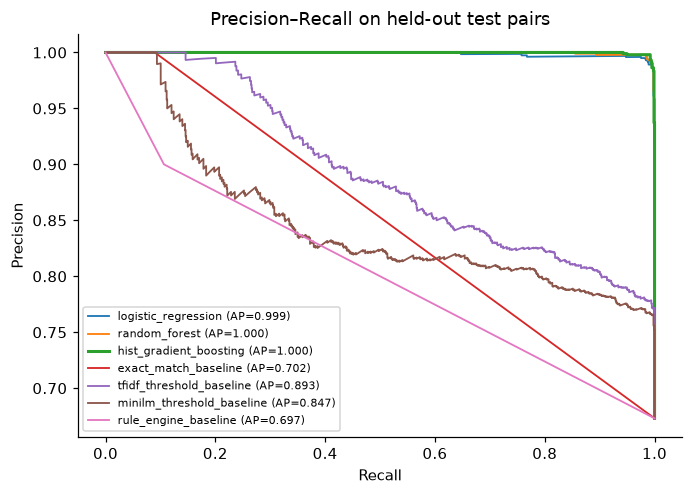

In [8]:
tt = R["test_table"][["precision", "recall", "f1", "accuracy", "roc_auc", "pr_auc", "true_positives", "false_positives", "true_negatives", "false_negatives"]]
display(tt.round(4))

from sklearn.metrics import precision_recall_curve
te = R["masks"]["test"]; y_te = y_all[te]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for name, s in R["test_scores"].items():
    p, r, _ = precision_recall_curve(y_te, s)
    ax.plot(r, p, label=f"{name} (AP={tt.loc[name, 'pr_auc']:.3f})", lw=2 if name == R["best_name"] else 1.2)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision–Recall on held-out test pairs"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_precision_recall_test.png", bbox_inches="tight"); plt.show()

---
## Section F — Deployed decision policy (precision-first, three-way)
The classifier probability is wrapped in safety gates that encode the project's annotation policy:
1. explicit canonical specification conflict → **NOT_EQUIVALENT**
2. p ≤ `t_low` → **NOT_EQUIVALENT**
3. p ≥ `t_high` **and** both records carry identity specifications (size / rating / standard / grade) that are not stated on one side only → **EQUIVALENT**
4. everything else (generic titles such as `AIR COMPRESSOR`, asymmetric specs, mid-range scores) → **NEEDS_REVIEW**

Deployed-policy outcome on held-out test pairs:


,value
n,1508.000000
auto_merge_count,401.000000
auto_reject_count,491.000000
review_count,616.000000
review_rate,0.408488
auto_merge_precision,0.995012
auto_reject_npv,0.987780
auto_merge_recall,0.393103


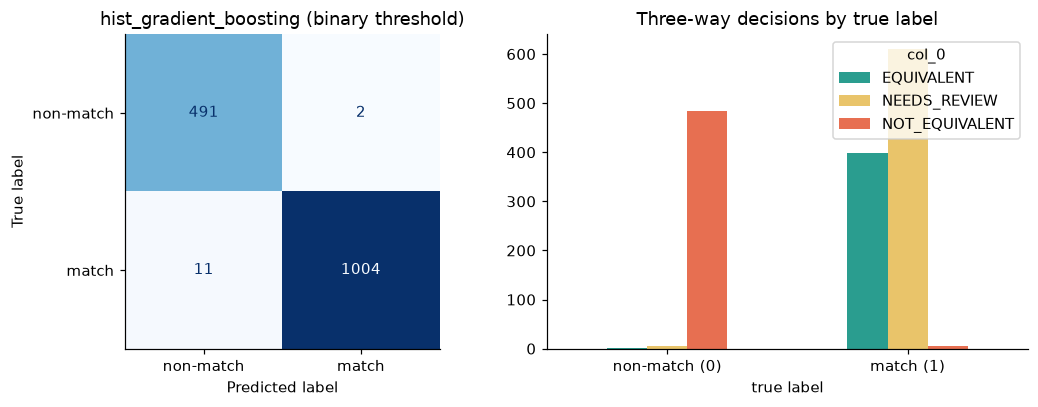

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
print("Deployed-policy outcome on held-out test pairs:")
display(pd.Series(R["test_policy"]).to_frame("value"))
pred = (R["test_scores"][R["best_name"]] >= R["hybrid"].thresholds["binary"]).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["non-match", "match"], ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title(f"{R['best_name']} (binary threshold)")
ct = pd.crosstab(pd.Series(y_te, name="true label"), R["test_decisions"]["decision"].values)
ct.plot.bar(ax=ax[1], color={"EQUIVALENT": "#2a9d8f", "NEEDS_REVIEW": "#e9c46a", "NOT_EQUIVALENT": "#e76f51"})
ax[1].set_title("Three-way decisions by true label"); ax[1].set_xticklabels(["non-match (0)", "match (1)"], rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_confusion_and_policy_test.png", bbox_inches="tight"); plt.show()

---
## Section G — Error analysis
**Which specification changes does the model catch?** Mutation groups marked *unseen* (orientation, drive, cooling, mobility, actuation, AC/DC, duty) are deliberately **not** encoded as explicit features — detecting them measures generalisation from lexical evidence alone.

In [10]:
display(R["mutation_table"].round(3))
print(f"Detection rate on mutation groups unseen by explicit features: {R['metrics']['unseen_mutation_detection_rate']:.3f}")
print("\nPositive recall by augmentation type (robustness to formatting noise):")
display(R["augmentation_table"].round(3))

,mutation_kind,mutation_group,n,detected,detection_rate
26,random,random,182,182,1.000
16,numeric,FACTOR,62,62,1.000
20,numeric,MM,48,48,1.000
18,numeric,KV,24,24,1.000
27,real_conflict,real_conflict,22,22,1.000
0,descriptor,actuation,18,18,1.000
11,descriptor,pipe_construction,15,15,1.000
17,numeric,INCH,15,15,1.000
12,descriptor,pump_type,14,14,1.000
8,descriptor,material_family,13,13,1.000


Detection rate on mutation groups unseen by explicit features: 1.000

Positive recall by augmentation type (robustness to formatting noise):


,augmentation,n,recall
1,quantity_suffix,375,0.995
0,boilerplate_prefix,327,0.985
5,typo,288,0.983
8,punctuation,224,0.991
2,noun_first_reorder,203,1.000
7,filler_drop,159,0.987
6,plural,139,0.993
3,abbreviation,114,0.921
4,unit_format,109,1.000
9,casing,94,0.989


In [11]:
# Misclassified test pairs (binary threshold) — the honest failure cases
tp = R["pairs"][te].copy(); tp["p_match"] = R["test_scores"][R["best_name"]]
tp["pred"] = (tp.p_match >= R["hybrid"].thresholds["binary"]).astype(int)
err = tp[tp.pred != tp.label]
print(f"Errors: {len(err)} of {len(tp)} test pairs")
display(err[["source", "label", "p_match", "text_a", "text_b", "aug_ops_b", "mutation_group"]].sort_values("p_match").head(15))

Errors: 13 of 1508 test pairs


,source,label,p_match,text_a,text_b,aug_ops_b,mutation_group
2298,synthetic_positive,1,0.001050,API FLUID LOSS FILTER PRESS WITH DEAD WEIGHT HYDRAULIC ASSEMBLY,API FLUID LOSS FILTER PRESS DEAD WEIGHT HYDRAULIC ASSY (NUMBERS.),quantity_suffix|filler_drop|abbreviation,
7177,synthetic_positive,1,0.021431,PROPOSAL FOR HIRING SERVICE FOR PAINTING IN EXHAUST PIPES (HEAT RE...,SUPPYL OF PROPOSAL FOR HIRING SERVICE FOR PAINTING IN EXHAUST PIPE...,boilerplate_prefix|typo|filler_drop,
7771,synthetic_positive,1,0.025755,SERVICE CONTRACT FOR INSTALLATION/RELOCATION / MODIFICATION OF SUR...,SERVICE CONTRACT FOR INSTALLATION/RELOCATION / MODIFICATION OF SUR...,punctuation|abbreviation|boilerplate_prefix,
1881,synthetic_positive,1,0.026426,ESP VACUUM PUMP ASSEMBLY AND SPARES,PURCHASE OF ESP VACUUM PUMP ASSY AND SPARE,abbreviation|plural|boilerplate_prefix,
2640,synthetic_positive,1,0.036836,HIRING AMC SERVICE AND BREAKDOWN MAINTENANCE SERVICES OF 8 NUMBERS...,HIRING AMC SERVICCE AND BREAKDOWN MAINTENANCE SERVICES OF 8 NUMBER...,abbreviation|typo|casing,
1679,synthetic_positive,1,0.171828,APPLICATION PAINT ON STEEL STRUCTURES PIPELINES & EQUIPMENT,APPLICATION OF PAINT ON STEEL STRUCTURES PIPELINES & EQPT,abbreviation,
2347,synthetic_positive,1,0.269109,COMPLETER COUPLING ASSEMBLY AND THEIR SPARES FOR CRUDE OIL DISPATC...,COMPLETER COUPLING ASSY AND THEIR SPARES FOR CRUDE OIL DISPATCH PU...,quantity_suffix|abbreviation,
7891,synthetic_positive,1,0.272675,SUPPLY AND FILLING WITH OUTSOURCED SELECTED EARTH INCLUDING NECESS...,SUPPLY AND FILLING WITH OUTSOURCED SELECTED EARTH INCLUDING NECESS...,typo|abbreviation|punctuation,
6170,synthetic_positive,1,0.760810,1 ONE NUMBER. 6 MULTIPLY 4 DRIVE TRACTOR PRIME MOVER UNIT OF MINIM...,1 ONE NUMBER. 6 MULTIPLY 4 DRIVE TRACTOR PRIME MOVER UNIT OF MINIM...,abbreviation,
1422,synthetic_positive,1,0.772398,NATURAL CIRCULATION STEAM GENERATOR HAVING RATED CAPACITY OF 90 MW...,NATURAL CIRCULATION STEAM GENERATOR HAVING RATED CAPACITY OF 90 MW...,typo|boilerplate_prefix,


---
## Section H — What the model relies on (permutation importance, PR-AUC drop on test)

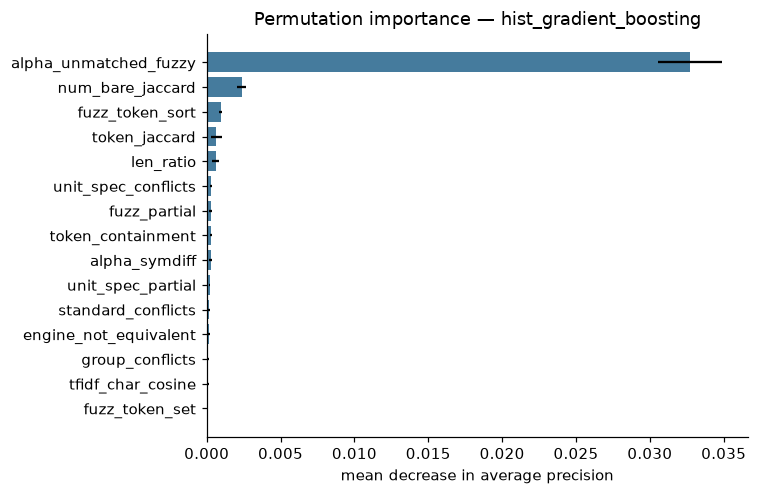

In [12]:
imp = R["importance"].head(15)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp.feature[::-1], imp.importance_mean[::-1], xerr=imp.importance_std[::-1], color="#457b9d")
ax.set_xlabel("mean decrease in average precision"); ax.set_title(f"Permutation importance — {R['best_name']}")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_feature_importance.png", bbox_inches="tight"); plt.show()

---
## Section I — Load the saved model and score new description pairs

In [13]:
from src.er_pipeline import load_model, match_descriptions, MODEL_PATH
model = load_model()
print("Loaded:", MODEL_PATH.name, "| version:", model.metadata.get("model_name"), model.VERSION)
demo = [
    ("CENTRIFUGAL PUMP API 610 60 M3/HR", "PUMP-CENTRIFUGAL, API 610, 60 M3/HR"),
    ("CONVEYOR BELT 1200MM WIDTH NN/EP", "CONVEYOR BELT 1600MM WIDTH NN/EP"),
    ("GATE VALVE SS304 2INCH CLASS 150 FLANGED", "GATE VALVE SS316 2INCH CLASS 150 FLANGED"),
    ("BALL VALVE 2 INCH 150# API 6D", "Supply of API 6D Ball Valves 2\" Class 150 (10 Nos)"),
    ("XLPE CABLE 3C X 400 SQMM 1.1KV ARMOURED", "XLPE CABLE 4C X 400 SQMM 1.1KV ARMOURED"),
    ("AIR COMPRESSOR", "AIR COMPRESSOR"),
    ("DIESEL DRIVEN FIRE WATER PUMP", "ELECTRIC DRIVEN FIRE WATER PUMP"),
]
rows = []
for a, b in demo:
    d = match_descriptions(a, b, model=model, lookup=R["lookup"])
    rows.append({"description A": a, "description B": b, "P(match)": d["match_probability"], "decision": d["decision"], "reason": d["reason"]})
display(pd.DataFrame(rows))

Loaded: hybrid_er_model.joblib | version: hist_gradient_boosting 2.0.0-hybrid-self-supervised


,description A,description B,P(match),decision,reason
0,CENTRIFUGAL PUMP API 610 60 M3/HR,"PUMP-CENTRIFUGAL, API 610, 60 M3/HR",0.9999,EQUIVALENT,"High match probability (1.000) with shared, non-conflicting specif..."
1,CONVEYOR BELT 1200MM WIDTH NN/EP,CONVEYOR BELT 1600MM WIDTH NN/EP,0.0000,NOT_EQUIVALENT,Explicit specification conflict: unit_spec_conflicts
2,GATE VALVE SS304 2INCH CLASS 150 FLANGED,GATE VALVE SS316 2INCH CLASS 150 FLANGED,0.0032,NOT_EQUIVALENT,Explicit specification conflict: grade_conflicts
3,BALL VALVE 2 INCH 150# API 6D,"Supply of API 6D Ball Valves 2"" Class 150 (10 Nos)",0.9970,EQUIVALENT,"High match probability (0.997) with shared, non-conflicting specif..."
4,XLPE CABLE 3C X 400 SQMM 1.1KV ARMOURED,XLPE CABLE 4C X 400 SQMM 1.1KV ARMOURED,0.0001,NOT_EQUIVALENT,Explicit specification conflict: unit_spec_conflicts
5,AIR COMPRESSOR,AIR COMPRESSOR,1.0000,NEEDS_REVIEW,High similarity (1.000) but generic title: no size/rating/standard...
6,DIESEL DRIVEN FIRE WATER PUMP,ELECTRIC DRIVEN FIRE WATER PUMP,0.4768,NEEDS_REVIEW,Uncertain match probability (0.477)


---
## Summary
* A real, trained entity-resolution model now exists: `models/hybrid_er_model.joblib` (classifier + TF-IDF models + thresholds + metadata).
* It was trained **without** any human or AI label — labels come from how the pairs were constructed — and evaluated on a group-disjoint held-out split.
* On held-out pairs it far exceeds the exact-match baseline and every single-signal baseline (see Section E); the deployed three-way policy trades recall for precision by routing generic or asymmetric descriptions to human review.
* Notebook 07 evaluates the model against the **review-set labels (AI-assisted, not independent human ground truth)**, reports cluster purity, and analyses the 22,464 real candidate pairs.